# WP08 — İlk B1/B2 L2-lojistik regresyon baseline sonuçları

**Görev:** Yeni ilaçlarda SIDER'da gözlenen ilaç–yan etki kayıt ilişkilerini sıralamak. Binary proxy `s=1` kaynakta gözlenen kayıt; `s=0` kaydı olmayan çifttir. **Unknown doğrulanmış biyolojik negatif değildir. Klinik risk, özgüllük veya kalibrasyon iddiası yoktur.**

Bu notebook eğitim üreticisini yeniden çalıştırmaz. Kilitli connectivity 5×3 nested CV, seed 20261106, train-only 5 ilaç/2 grup PT sözlüğü, hazırlanmış dönüşüm ve eligibility dosyaları korunarak tamamlanan deneyin sonuçlarını okur. Ana protokol ve scaffold OR >=0,8 stres sonucu ayrı kalır. ATC/RF/MLP/PPI/context eklenmedi. Önceden keşfedilmiş 62 ilaçta iç doğrulamadır.

In [1]:
from pathlib import Path
import json,numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():ROOT=ROOT.parent
QA=ROOT/'reports/qa/WP08/baseline_v1';FIG=ROOT/'reports/figures/WP08/baseline_v1';FIG.mkdir(parents=True,exist_ok=True)
pd.set_option('display.max_rows',170);pd.set_option('display.max_columns',22);pd.set_option('display.max_colwidth',100)
def read(n):return pd.read_csv(QA/n,keep_default_na=False)
run=json.loads((QA/'run_config.json').read_text(encoding='utf-8'));training=json.loads((QA/'training_complete.json').read_text(encoding='utf-8'))
display(pd.DataFrame([training]));display(read('environment.json') if False else pd.DataFrame([json.loads((QA/'environment.json').read_text(encoding='utf-8'))]))
display(read('fold_train_validation_test_scope.csv'))

,model_version,classifier_fits_attempted,outer_bundles,OOF_scored_pairs,prior_files_verified,elapsed_seconds,selected_C_sha256,semantics,WP09_started
0,WP08-observed-record-L2LR-v1,47031,40,70683,483,97.781856,5e20e8df3aa05d2a74cf67eb3abae565fe13fd6ad339eefebe6800ac431ff2c6,Observed SIDER record ranking proxy; unknown is NOT a verified biological negative; not clinical...,False


,python,numpy,scipy,sklearn,threadpool_limit,new_packages_installed,model_version,semantics
0,3.11.3,2.4.6,1.17.1,1.9.0,1,False,WP08-observed-record-L2LR-v1,Observed SIDER record ranking proxy; unknown is NOT a verified biological negative; not clinical...


,context,protocol,outer_fold,inner_fold,train_drugs,validation_drugs,test_drugs,train_graph_drugs,train_graph_proteins,train_graph_edges,chemistry_fit_drugs,protein_fit_accessions,semantics
0,primary_o01_final,primary,1,0,49,0,13,49,125,354,43,125,Observed SIDER record ranking proxy; unknown is NOT a verified biological negative; not clinical...
1,primary_o01_i01,primary,1,1,32,17,13,32,92,234,29,92,Observed SIDER record ranking proxy; unknown is NOT a verified biological negative; not clinical...
2,primary_o01_i02,primary,1,2,33,16,13,33,111,250,29,111,Observed SIDER record ranking proxy; unknown is NOT a verified biological negative; not clinical...
3,primary_o01_i03,primary,1,3,33,16,13,33,92,224,28,92,Observed SIDER record ranking proxy; unknown is NOT a verified biological negative; not clinical...
4,primary_o02_final,primary,2,0,49,0,13,49,121,377,43,121,Observed SIDER record ranking proxy; unknown is NOT a verified biological negative; not clinical...
5,primary_o02_i01,primary,2,1,32,17,13,32,92,233,29,92,Observed SIDER record ranking proxy; unknown is NOT a verified biological negative; not clinical...
6,primary_o02_i02,primary,2,2,33,16,13,33,106,270,30,106,Observed SIDER record ranking proxy; unknown is NOT a verified biological negative; not clinical...
7,primary_o02_i03,primary,2,3,33,16,13,33,96,251,27,96,Observed SIDER record ranking proxy; unknown is NOT a verified biological negative; not clinical...
8,primary_o03_final,primary,3,0,50,0,12,50,133,398,43,133,Observed SIDER record ranking proxy; unknown is NOT a verified biological negative; not clinical...
9,primary_o03_i01,primary,3,1,33,17,12,33,103,282,31,103,Observed SIDER record ranking proxy; unknown is NOT a verified biological negative; not clinical...


## 1. C yalnız iç doğrulamayla seçildi

Her inner fold içinde aynı C adayları aynı kullanılabilir ilaçlar ve C'den bağımsız hedef kümesiyle karşılaştırılır. Farklı inner foldlarda sözlükler değişebilir; bu nedenle skorların görevi folda özgü train destek kuralına koşulludur. Üç geçerli foldun drug-macro AP ortalaması seçim ölçütüdür; NA sıfır sayılmaz. Eşitlikte küçük C. Tüm inner seçimler tamamlanıp hash'le kaydedilmeden outer test skorlanmadı.

,protocol,outer_fold,family,model,selected_C,valid_inner_folds,C0.1_mean_drug_AP,C1_mean_drug_AP,C10_mean_drug_AP,status
0,primary,1,PT,B1,0.1,3,0.661508,0.659226,0.654025,selected_inner_only
1,primary,1,PT,B2,0.1,3,0.617386,0.577824,0.555074,selected_inner_only
2,primary,1,historical30,B1,10.0,3,0.844766,0.844614,0.844902,selected_inner_only
3,primary,1,historical30,B2,0.1,3,0.819761,0.796749,0.782040,selected_inner_only
4,primary,2,PT,B1,0.1,3,0.687624,0.683579,0.666498,selected_inner_only
5,primary,2,PT,B2,0.1,3,0.636377,0.604628,0.579670,selected_inner_only
6,primary,2,historical30,B1,1.0,3,0.869595,0.870905,0.865374,selected_inner_only
7,primary,2,historical30,B2,0.1,3,0.869602,0.856280,0.838810,selected_inner_only
8,primary,3,PT,B1,1.0,3,0.676392,0.676917,0.659412,selected_inner_only
9,primary,3,PT,B2,0.1,3,0.628353,0.596705,0.572322,selected_inner_only


,protocol,outer_fold,inner_fold,context,family,model,C,drug_macro_AP,valid_drugs,validation_input_drugs,scoring_classes,candidate_fitted_classes,scope_hash,excluded_from_C_comparison
0,primary,1,1,primary_o01_i01,PT,B1,0.1,0.693110,14,14,157,157,34d2f80b6a5fa8065d60967bc16d57ef6899d289bebc6839451e7601d1ffe844,0
1,primary,1,1,primary_o01_i01,PT,B1,1.0,0.693587,14,14,157,157,34d2f80b6a5fa8065d60967bc16d57ef6899d289bebc6839451e7601d1ffe844,0
2,primary,1,1,primary_o01_i01,PT,B1,10.0,0.684179,14,14,157,157,34d2f80b6a5fa8065d60967bc16d57ef6899d289bebc6839451e7601d1ffe844,0
3,primary,1,2,primary_o01_i02,PT,B1,0.1,0.586129,14,14,178,178,90774c48417b85942a4df908b160d3e7bfc989eac432d7d8ef668c46ccb056c8,2
4,primary,1,2,primary_o01_i02,PT,B1,1.0,0.588881,14,14,178,178,90774c48417b85942a4df908b160d3e7bfc989eac432d7d8ef668c46ccb056c8,2
5,primary,1,2,primary_o01_i02,PT,B1,10.0,0.585981,14,14,178,178,90774c48417b85942a4df908b160d3e7bfc989eac432d7d8ef668c46ccb056c8,2
6,primary,1,3,primary_o01_i03,PT,B1,0.1,0.705285,15,15,134,134,d71d469028d30c168f5a21d4e6afac6f7f2604078435735fce848ecf7aea5787,0
7,primary,1,3,primary_o01_i03,PT,B1,1.0,0.695209,15,15,134,134,d71d469028d30c168f5a21d4e6afac6f7f2604078435735fce848ecf7aea5787,0
8,primary,1,3,primary_o01_i03,PT,B1,10.0,0.691913,15,15,134,134,d71d469028d30c168f5a21d4e6afac6f7f2604078435735fce848ecf7aea5787,0
9,primary,1,1,primary_o01_i01,PT,B2,0.1,0.655685,16,16,171,171,9aaae824ef8fe401b855c72150e9381136a83d06a22591690f9af7ff9fe4ef93,0


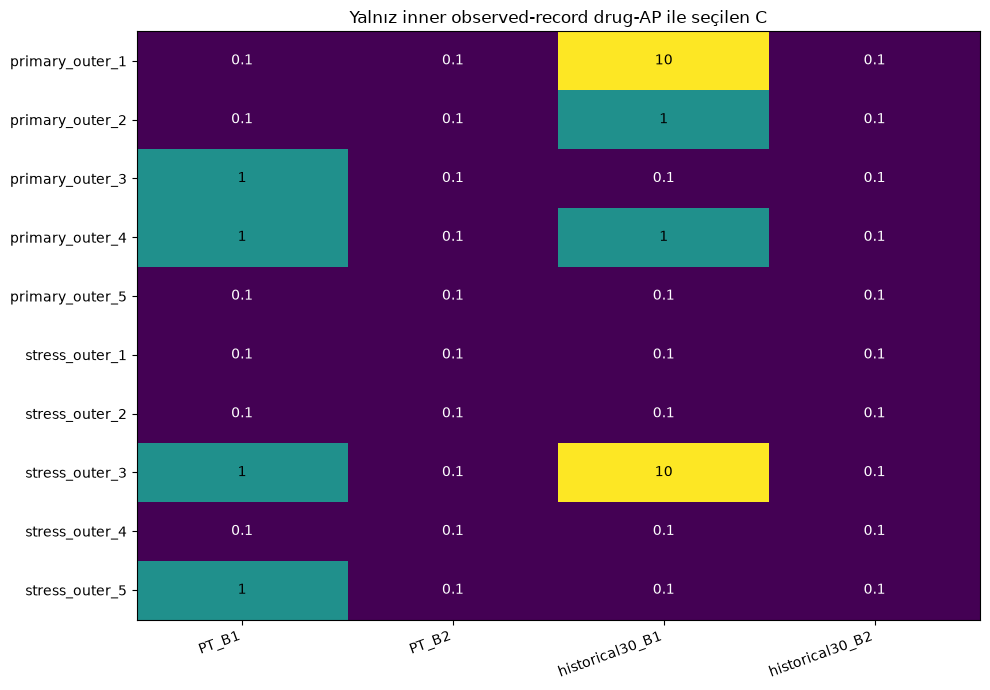

In [2]:
selection=read('selected_C.csv');inner=read('inner_selection_metrics.csv');display(selection.drop(columns=['semantics']));display(inner.head(12).drop(columns=['semantics']))
grid=selection.assign(row=selection.protocol+'_outer_'+selection.outer_fold.astype(str),col=selection.family+'_'+selection.model).pivot(index='row',columns='col',values='selected_C')
fig,ax=plt.subplots(figsize=(10,7));im=ax.imshow(np.log10(grid.to_numpy(dtype=float)),cmap='viridis',vmin=-1,vmax=1,aspect='auto');ax.set_xticks(range(len(grid.columns)),grid.columns,rotation=20,ha='right');ax.set_yticks(range(len(grid)),grid.index)
for i in range(len(grid)):
    for j in range(len(grid.columns)):ax.text(j,i,f'{grid.iloc[i,j]:g}',ha='center',va='center',color='white' if grid.iloc[i,j]<1 else 'black')
ax.set_title('Yalnız inner observed-record drug-AP ile seçilen C');plt.tight_layout();plt.savefig(FIG/'01_inner_selected_C.png',dpi=160);plt.show()

**Yorum:** B2 her ana outer fold için C=0,1 seçti; B1'de seçim folda göre 0,1 veya 1. Bu sonuçtan sonra C aralığı genişletilmedi. 40.611 inner ve 6.133 outer tek-PT/kategori sınıflandırıcısı fit edildi; bunlar ilaç veya bağımsız deney sayısı değildir. 279 inner aday sınıf fit'i ve sekiz outer sınıf fit'i tek proxy sonucu nedeniyle yapılmadı. Yakınsama/fit hatası gözlenmedi. 400 parametre bundle'ı seçim iziyle saklandı.

## 2. Ana PT görevi: outer test fold sonuçları

,protocol,family,scope,model,outer_fold,metric,estimate,scored_drugs,drug_AP_evaluable,scored_pairs,observed_positive_scored,CI_NA_reason
0,primary,PT,own,B1,1,drug_macro_AP,0.739874,11,11,2420,919,Per-fold CI not estimated; overlapping fitted folds are not independent; group-resampled OOF CI ...
5,primary,PT,own,B1,2,drug_macro_AP,0.622411,11,11,2882,657,Per-fold CI not estimated; overlapping fitted folds are not independent; group-resampled OOF CI ...
10,primary,PT,own,B1,3,drug_macro_AP,0.597787,11,11,2937,738,Per-fold CI not estimated; overlapping fitted folds are not independent; group-resampled OOF CI ...
15,primary,PT,own,B1,4,drug_macro_AP,0.600458,10,10,2700,660,Per-fold CI not estimated; overlapping fitted folds are not independent; group-resampled OOF CI ...
20,primary,PT,own,B1,5,drug_macro_AP,0.712663,11,11,3025,846,Per-fold CI not estimated; overlapping fitted folds are not independent; group-resampled OOF CI ...
25,primary,PT,own,B2,1,drug_macro_AP,0.741120,13,13,3120,1212,Per-fold CI not estimated; overlapping fitted folds are not independent; group-resampled OOF CI ...
30,primary,PT,own,B2,2,drug_macro_AP,0.608591,13,13,3718,916,Per-fold CI not estimated; overlapping fitted folds are not independent; group-resampled OOF CI ...
35,primary,PT,own,B2,3,drug_macro_AP,0.577597,11,11,3498,767,Per-fold CI not estimated; overlapping fitted folds are not independent; group-resampled OOF CI ...
40,primary,PT,own,B2,4,drug_macro_AP,0.536424,12,12,3756,786,Per-fold CI not estimated; overlapping fitted folds are not independent; group-resampled OOF CI ...
45,primary,PT,own,B2,5,drug_macro_AP,0.615281,12,12,3912,895,Per-fold CI not estimated; overlapping fitted folds are not independent; group-resampled OOF CI ...


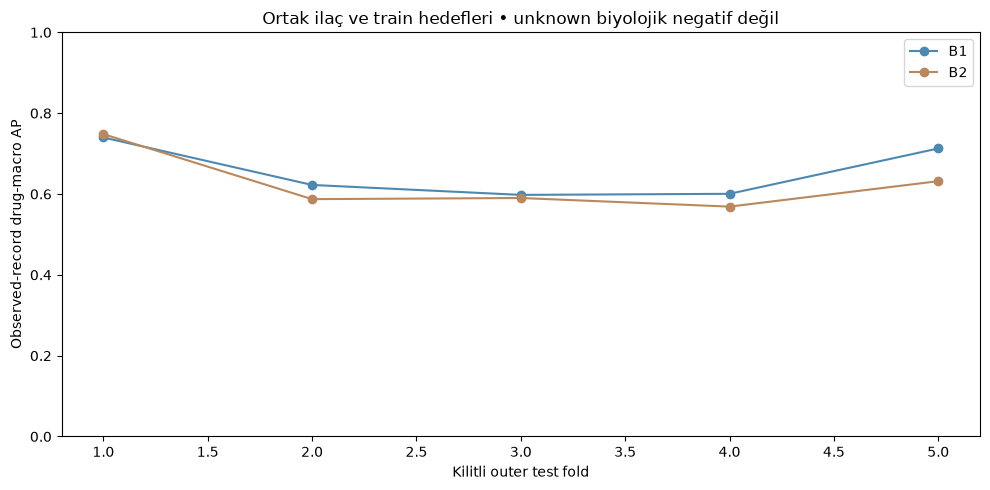

,context,protocol,outer_fold,family,model,selected_C,train_input_drugs,declared_targets,fitted_targets,test_cohort_drugs,test_input_eligible,parameters_file
0,primary_o01_final,primary,1,PT,B1,0.1,43,220,220,13,11,models\WP08_baseline_v1\primary_o01_final_PT_B1_selected.npz
1,primary_o01_final,primary,1,PT,B2,0.1,48,240,240,13,13,models\WP08_baseline_v1\primary_o01_final_PT_B2_selected.npz
2,primary_o01_final,primary,1,historical30,B1,10.0,43,30,30,13,11,models\WP08_baseline_v1\primary_o01_final_historical30_B1_selected.npz
3,primary_o01_final,primary,1,historical30,B2,0.1,48,30,30,13,13,models\WP08_baseline_v1\primary_o01_final_historical30_B2_selected.npz
4,primary_o02_final,primary,2,PT,B1,0.1,43,262,262,13,11,models\WP08_baseline_v1\primary_o02_final_PT_B1_selected.npz
5,primary_o02_final,primary,2,PT,B2,0.1,48,286,286,13,13,models\WP08_baseline_v1\primary_o02_final_PT_B2_selected.npz
6,primary_o02_final,primary,2,historical30,B1,1.0,43,30,30,13,11,models\WP08_baseline_v1\primary_o02_final_historical30_B1_selected.npz
7,primary_o02_final,primary,2,historical30,B2,0.1,48,30,30,13,13,models\WP08_baseline_v1\primary_o02_final_historical30_B2_selected.npz
8,primary_o03_final,primary,3,PT,B1,1.0,43,268,267,12,11,models\WP08_baseline_v1\primary_o03_final_PT_B1_selected.npz
9,primary_o03_final,primary,3,PT,B2,0.1,50,319,318,12,11,models\WP08_baseline_v1\primary_o03_final_PT_B2_selected.npz


In [3]:
folds=read('outer_fold_metrics.csv');display(folds[(folds.protocol=='primary') & (folds.family=='PT') & (folds.metric=='drug_macro_AP')].drop(columns=['semantics','CI95_low','CI95_high']))
fig,ax=plt.subplots(figsize=(10,5))
f=folds[(folds.protocol=='primary') & (folds.family=='PT') & (folds.scope=='paired54') & (folds.metric=='drug_macro_AP')]
for model,color in [('B1','#4d88b1'),('B2','#bb885d')]:
    a=f[f.model.eq(model)].sort_values('outer_fold');ax.plot(a.outer_fold,a.estimate,'o-',label=model,color=color)
ax.set(ylim=(0,1),xlabel='Kilitli outer test fold',ylabel='Observed-record drug-macro AP',title='Ortak ilaç ve train hedefleri • unknown biyolojik negatif değil');ax.legend();plt.tight_layout();plt.savefig(FIG/'02_outer_fold_PT_AP.png',dpi=160);plt.show()
display(read('outer_model_coverage.csv').drop(columns=['semantics']))

**Yorum:** Fold farkları küçük örneklem, input kapsamı ve train'den öğrenilen hedef sözlüğü farklarını birlikte yansıtır. Foldları bağımsız beş tekrar gibi test etmek doğru değildir; eğitim kümeleri örtüşür. Tek bir iyi/kötü fold seçilmedi. Bu grafiğe ayrı fold CI verilmedi; CI gerekçesi tabloda ve grup-resampled OOF özette belirtilir.

## 3. PT: kendi kapsamı, ortak 54 ve complete-case 53

,protocol,family,scope,model,metric,estimate,CI95_low,CI95_high,valid_bootstrap_replicates,CI_NA_reason
0,primary,PT,own,B1,drug_macro_AP,0.655642,0.613111,0.692041,1000,
1,primary,PT,own,B1,micro_AP,0.542199,0.482731,0.611801,1000,
2,primary,PT,own,B1,class_macro_AP,0.315224,0.299680,0.394727,1000,
3,primary,PT,own,B1,micro_AUROC,0.726914,0.692100,0.765193,1000,
4,primary,PT,own,B1,class_macro_AUROC,0.481439,0.428299,0.533029,1000,
5,primary,PT,own,B2,drug_macro_AP,0.618365,0.572377,0.661426,1000,
6,primary,PT,own,B2,micro_AP,0.534207,0.479969,0.590421,1000,
7,primary,PT,own,B2,class_macro_AP,0.351038,0.330785,0.429181,1000,
8,primary,PT,own,B2,micro_AUROC,0.733299,0.698257,0.770078,1000,
9,primary,PT,own,B2,class_macro_AUROC,0.563063,0.521847,0.606170,1000,


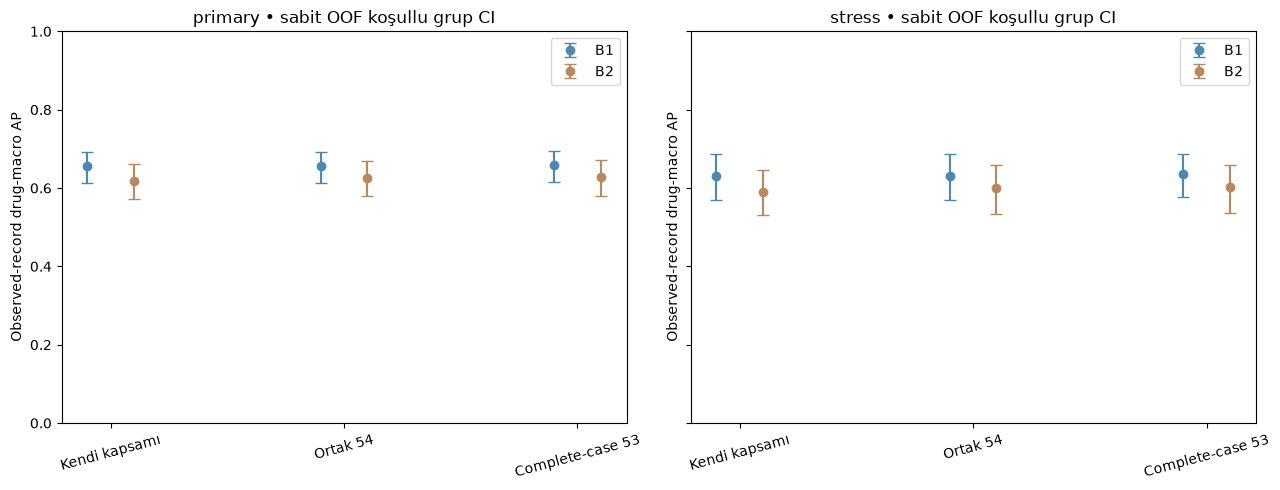

,protocol,family,scope,model,cohort_drugs,input_scope_name,scored_drugs,drug_AP_evaluable,drug_AP_NA,scored_pairs,observed_positive_scored,unknown_scored_NOT_verified_negative,source_positive_for_scored_drugs,out_of_scored_vocab_positive,classes_with_any_score,class_AP_AUROC_evaluable,class_metric_NA
0,primary,PT,own,B1,62,own,54,54,8,13964,3820,10144,5505,1685,306,256,50
1,primary,PT,own,B2,62,own,61,61,1,18004,4576,13428,6405,1829,350,293,57
2,primary,PT,paired54,B1,62,paired54,54,54,8,13964,3820,10144,5505,1685,306,256,50
3,primary,PT,paired54,B2,62,paired54,54,54,8,13964,3820,10144,5505,1685,306,256,50
4,primary,PT,complete_case53,B1,62,complete_case53,53,53,9,13694,3730,9964,5347,1617,306,256,50
5,primary,PT,complete_case53,B2,62,complete_case53,53,53,9,13694,3730,9964,5347,1617,306,256,50
12,stress,PT,own,B1,62,own,54,54,8,13890,3751,10139,5505,1754,307,257,50
13,stress,PT,own,B2,62,own,61,61,1,17970,4569,13401,6405,1836,351,300,51
14,stress,PT,paired54,B1,62,paired54,54,54,8,13890,3751,10139,5505,1754,307,257,50
15,stress,PT,paired54,B2,62,paired54,54,54,8,13890,3751,10139,5505,1754,307,257,50


In [4]:
metrics=read('oof_metrics_with_group_CI.csv');coverage=read('evaluation_coverage.csv')
display(metrics[(metrics.family=='PT')].drop(columns=['semantics','CI_interpretation']))
fig,axs=plt.subplots(1,2,figsize=(13,5),sharey=True)
for ax,protocol in zip(axs,['primary','stress']):
    f=metrics[(metrics.protocol==protocol)&(metrics.family=='PT')&(metrics.metric=='drug_macro_AP')]
    for model,offset,color in [('B1',-.1,'#4d88b1'),('B2',.1,'#bb885d')]:
        a=f[f.model.eq(model)].set_index('scope').loc[['own','paired54','complete_case53']];xx=np.arange(3)+offset
        ax.errorbar(xx,a.estimate,yerr=np.vstack([a.estimate-a.CI95_low,a.CI95_high-a.estimate]).astype(float),fmt='o',capsize=4,label=model,color=color)
    ax.set_xticks(range(3),['Kendi kapsamı','Ortak 54','Complete-case 53'],rotation=15);ax.set(title=protocol+' • sabit OOF koşullu grup CI',ylim=(0,1),ylabel='Observed-record drug-macro AP');ax.legend()
plt.tight_layout();plt.savefig(FIG/'03_PT_AP_group_CI.png',dpi=160);plt.show()
display(coverage[coverage.family.eq('PT')].drop(columns=['semantics']))

**Yorum:** Ana protokol ortak 54 ilaç/ortak train hedeflerinde B1 AP≈0,656, B2≈0,626. Kendi kapsamlarında B1 54, B2 61 ilaç skorlar; iki farklı kapsamın ham metrik farkı eşleştirilmiş kıyas değildir. Complete-case 53, aynı fit edilmiş modellerin test alt kümesi duyarlılığıdır; 53 ilaçla yeniden eğitilmiş ayrı model yoktur.

CI, 1000 kez kilitli yapısal grup örneklemesiyle sabit OOF tahminlerine koşulludur. İlaç–PT çiftleri veya foldlar bağımsız örneklenmedi. Bu aralık bütün tekrar eğitim/hiperparametre belirsizliğini veya yeni dış veri belirsizliğini kapsamaz. Farklı foldlarda farklı hedef sözlükleri olduğundan pooled micro/class ölçümler ragged kapsamlı, train-destek kuralına koşullu özetlerdir; sabit 1061-hedef başarımı gibi yorumlanmaz.

## 4. Tarihsel 30 ayrı karşılaştırmadır

,protocol,family,scope,model,metric,estimate,CI95_low,CI95_high,valid_bootstrap_replicates,CI_NA_reason
40,primary,historical30,paired54,B1,drug_macro_AP,0.889193,0.855212,0.918778,1000,
41,primary,historical30,paired54,B1,micro_AP,0.808555,0.767987,0.849219,1000,
42,primary,historical30,paired54,B1,class_macro_AP,0.556963,0.517687,0.627259,1000,
43,primary,historical30,paired54,B1,micro_AUROC,0.778868,0.749161,0.812425,1000,
44,primary,historical30,paired54,B1,class_macro_AUROC,0.498376,0.429267,0.566473,1000,
45,primary,historical30,paired54,B2,drug_macro_AP,0.862726,0.820551,0.898485,1000,
46,primary,historical30,paired54,B2,micro_AP,0.784803,0.727748,0.842383,1000,
47,primary,historical30,paired54,B2,class_macro_AP,0.590026,0.544496,0.674074,1000,
48,primary,historical30,paired54,B2,micro_AUROC,0.774438,0.734822,0.813276,1000,
49,primary,historical30,paired54,B2,class_macro_AUROC,0.580794,0.517439,0.636863,1000,


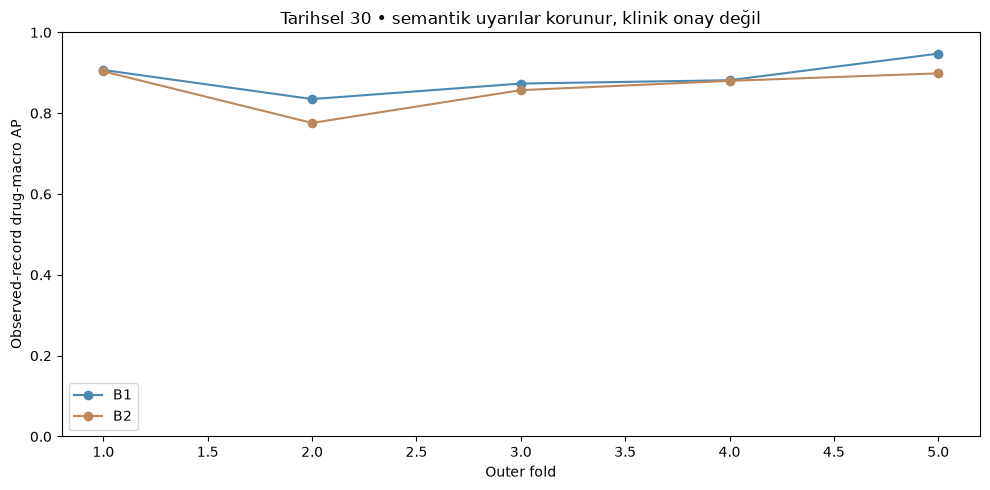

,protocol,family,scope,model,cohort_drugs,input_scope_name,scored_drugs,drug_AP_evaluable,drug_AP_NA,scored_pairs,observed_positive_scored,unknown_scored_NOT_verified_negative,source_positive_for_scored_drugs,out_of_scored_vocab_positive,classes_with_any_score,class_AP_AUROC_evaluable,class_metric_NA
6,primary,historical30,own,B1,62,own,54,53,9,1609,866,743,876,10,30,29,1
7,primary,historical30,own,B2,62,own,61,60,2,1819,996,823,1006,10,30,29,1
8,primary,historical30,paired54,B1,62,paired54,54,53,9,1609,866,743,876,10,30,29,1
9,primary,historical30,paired54,B2,62,paired54,54,53,9,1609,866,743,876,10,30,29,1
10,primary,historical30,complete_case53,B1,62,complete_case53,53,52,10,1579,850,729,860,10,30,29,1
11,primary,historical30,complete_case53,B2,62,complete_case53,53,52,10,1579,850,729,860,10,30,29,1
18,stress,historical30,own,B1,62,own,54,53,9,1609,866,743,876,10,30,29,1
19,stress,historical30,own,B2,62,own,61,60,2,1818,995,823,1006,11,30,29,1
20,stress,historical30,paired54,B1,62,paired54,54,53,9,1609,866,743,876,10,30,29,1
21,stress,historical30,paired54,B2,62,paired54,54,53,9,1609,866,743,876,10,30,29,1


In [5]:
hist=metrics[(metrics.family=='historical30') & (metrics.scope=='paired54')];display(hist.drop(columns=['semantics','CI_interpretation']))
fig,ax=plt.subplots(figsize=(10,5))
f=folds[(folds.protocol=='primary')&(folds.family=='historical30')&(folds.scope=='paired54')&(folds.metric=='drug_macro_AP')]
for model,color in [('B1','#4d88b1'),('B2','#bb885d')]:
    a=f[f.model.eq(model)].sort_values('outer_fold');ax.plot(a.outer_fold,a.estimate,'o-',label=model,color=color)
ax.set(ylim=(0,1),xlabel='Outer fold',ylabel='Observed-record drug-macro AP',title='Tarihsel 30 • semantik uyarılar korunur, klinik onay değil');ax.legend();plt.tight_layout();plt.savefig(FIG/'04_historical30_separate.png',dpi=160);plt.show()
display(coverage[coverage.family.eq('historical30')].drop(columns=['semantics']))

**Yorum:** Tarihsel 30 daha yoğun ve seçilmiş farklı bir etiket uzayıdır; PT ile sayısal AP farkı doğrudan daha iyi yöntem veya daha doğru klinik kategori anlamına gelmez. Renal impairment→Nefrotoksisite, birden fazla kavramın birleştirilmesi gibi önceki semantik uyarılar geçerlidir. Sulfanilamide'nin kategori pozitifinin olmaması gerçek negatiflik değildir; drug-AP desteği yoksa NA kalır.

## 5. Abstention, bilinmeyenler ve hesaplanamayan sınıflar

,protocol,outer_fold,family,model,drug_id,status,declared_targets,scored_targets
0,primary,1,PT,B1,DB00254,OOF_prediction_available,220,220
1,primary,1,PT,B1,DB00438,OOF_prediction_available,220,220
2,primary,1,PT,B1,DB00446,OOF_prediction_available,220,220
3,primary,1,PT,B1,DB00479,OOF_prediction_available,220,220
4,primary,1,PT,B1,DB00493,OOF_prediction_available,220,220
5,primary,1,PT,B1,DB00537,OOF_prediction_available,220,220
6,primary,1,PT,B1,DB00685,OOF_prediction_available,220,220
7,primary,1,PT,B1,DB01137,OOF_prediction_available,220,220
8,primary,1,PT,B1,DB01155,ABSTAIN_no_input,220,0
9,primary,1,PT,B1,DB01165,ABSTAIN_no_input,220,0


,phase,family,model,status,candidate_class_fits
0,inner,PT,B1,NA_single_proxy_outcome,72
1,inner,PT,B1,fitted,16440
2,inner,PT,B2,NA_single_proxy_outcome,69
3,inner,PT,B2,fitted,18909
4,inner,historical30,B1,NA_single_proxy_outcome,69
5,inner,historical30,B1,fitted,2631
6,inner,historical30,B2,NA_single_proxy_outcome,69
7,inner,historical30,B2,fitted,2631
8,outer,PT,B1,NA_single_proxy_outcome,2
9,outer,PT,B1,fitted,2581


,protocol,family,scope,model,class_id,scored_drugs,observed_positive,unobserved_NOT_verified_negative,AP,AUROC,NA_reason,CI_status
3,primary,PT,own,B1,C0001925,32,0,32,,,no_observed_positive,No per-class CI; sparse ragged support; aggregate conditional group-bootstrap CI reported separa...
4,primary,PT,own,B1,C0002170,21,0,21,,,no_observed_positive,No per-class CI; sparse ragged support; aggregate conditional group-bootstrap CI reported separa...
10,primary,PT,own,B1,C0003126,21,0,21,,,no_observed_positive,No per-class CI; sparse ragged support; aggregate conditional group-bootstrap CI reported separa...
22,primary,PT,own,B1,C0005758,11,0,11,,,no_observed_positive,No per-class CI; sparse ragged support; aggregate conditional group-bootstrap CI reported separa...
24,primary,PT,own,B1,C0005940,11,0,11,,,no_observed_positive,No per-class CI; sparse ragged support; aggregate conditional group-bootstrap CI reported separa...
34,primary,PT,own,B1,C0009421,10,0,10,,,no_observed_positive,No per-class CI; sparse ragged support; aggregate conditional group-bootstrap CI reported separa...
43,primary,PT,own,B1,C0011175,22,0,22,,,no_observed_positive,No per-class CI; sparse ragged support; aggregate conditional group-bootstrap CI reported separa...
44,primary,PT,own,B1,C0011570,21,0,21,,,no_observed_positive,No per-class CI; sparse ragged support; aggregate conditional group-bootstrap CI reported separa...
50,primary,PT,own,B1,C0011974,11,0,11,,,no_observed_positive,No per-class CI; sparse ragged support; aggregate conditional group-bootstrap CI reported separa...
64,primary,PT,own,B1,C0014724,10,0,10,,,no_observed_positive,No per-class CI; sparse ragged support; aggregate conditional group-bootstrap CI reported separa...


,protocol,family,scope,model,drug_id,scored_targets,observed_positive,unobserved_NOT_verified_negative,drug_AP,NA_reason,outer_fold,structural_group
375,primary,historical30,own,B1,DB00259,29,0,29,,no_observed_positive,3,connectivity_guard_003
393,primary,historical30,own,B1,DB00578,0,0,0,,no_scored_targets,5,connectivity_guard_021
403,primary,historical30,own,B1,DB00798,0,0,0,,no_scored_targets,4,connectivity_guard_031
409,primary,historical30,own,B1,DB00978,0,0,0,,no_scored_targets,2,connectivity_guard_037
411,primary,historical30,own,B1,DB01044,0,0,0,,no_scored_targets,2,connectivity_guard_039
417,primary,historical30,own,B1,DB01150,0,0,0,,no_scored_targets,4,connectivity_guard_045
418,primary,historical30,own,B1,DB01155,0,0,0,,no_scored_targets,1,connectivity_guard_046
419,primary,historical30,own,B1,DB01165,0,0,0,,no_scored_targets,1,connectivity_guard_044
433,primary,historical30,own,B1,DB06799,0,0,0,,no_scored_targets,3,connectivity_guard_060
437,primary,historical30,own,B2,DB00259,29,0,29,,no_observed_positive,3,connectivity_guard_003


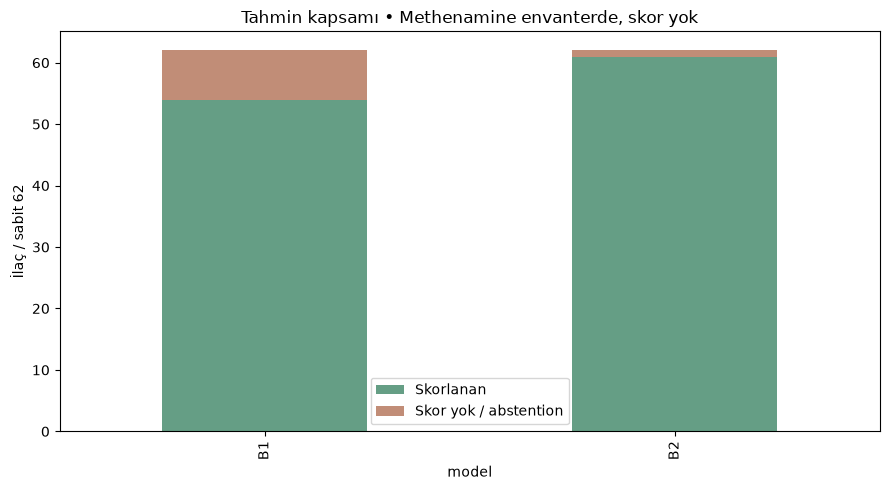

In [6]:
status=read('prediction_status_all62.csv');display(status[status.protocol.eq('primary')&status.family.eq('PT')].drop(columns=['semantics']))
display(read('fit_status_summary.csv').drop(columns=['semantics']))
cls=read('per_class_metrics.csv');display(cls[cls.protocol.eq('primary')&cls.family.eq('PT')&cls.AUROC.eq('')].head(12).drop(columns=['semantics']))
drug=read('per_drug_metrics.csv');display(drug[drug.protocol.eq('primary')&drug.family.eq('historical30')&drug.NA_reason.ne('')].head(12).drop(columns=['semantics']))
fig,ax=plt.subplots(figsize=(9,5));c=coverage[coverage.protocol.eq('primary')&coverage.family.eq('PT')&coverage.scope.eq('own')].set_index('model')
counts=pd.DataFrame({'Skorlanan':c.scored_drugs,'Skor yok / abstention':62-c.scored_drugs});counts.plot.bar(stacked=True,ax=ax,color=['#659e85','#c18d77']);ax.set(ylabel='İlaç / sabit 62',title='Tahmin kapsamı • Methenamine envanterde, skor yok');plt.tight_layout();plt.savefig(FIG/'05_prediction_coverage.png',dpi=160);plt.show()

**Yorum:** Methenamine için iki modelde de abstention; B1 sekiz kimya inceleme kaydında skor vermez. B2 protein dalıyla yedi ek ilaçta kayıt-sıralama skoru verebilir; bu ilave input kapsamı başarı artışı iddiası değildir. Kaynak 62 ID ve QC kararları değişmedi. Train tek proxy sınıfı, test sıfır gözlenen pozitif veya sıfır unknown gibi durumlarda fallback olasılık/başarım sıfırı üretilmedi. Sözlük dışı kaynak pozitif sayıları kapsam tablosunda ayrıca vardır.

## 6. Eşleştirilmiş fark ve koşullu belirsizlik

,protocol,family,scope,metric,B2_minus_B1,CI95_low,CI95_high,valid_bootstrap_replicates,CI_NA_reason
0,primary,PT,paired54,drug_macro_AP,-0.029403,-0.051084,-0.009335,1000,
1,primary,PT,paired54,micro_AP,-0.009864,-0.046018,0.022309,1000,
2,primary,PT,paired54,class_macro_AP,0.033685,0.006546,0.067637,1000,
3,primary,PT,paired54,micro_AUROC,-0.012409,-0.043231,0.018767,1000,
4,primary,PT,paired54,class_macro_AUROC,0.061622,0.003568,0.115124,1000,
5,primary,PT,complete_case53,drug_macro_AP,-0.029794,-0.051595,-0.009335,1000,
6,primary,PT,complete_case53,micro_AP,-0.011444,-0.048265,0.021149,1000,
7,primary,PT,complete_case53,class_macro_AP,0.033453,0.005361,0.066978,1000,
8,primary,PT,complete_case53,micro_AUROC,-0.019031,-0.047620,0.008339,1000,
9,primary,PT,complete_case53,class_macro_AUROC,0.060432,0.002449,0.115564,1000,


,protocol,family,scope,seed,reps,unique_groups,unit,draws_shared_across_B1_B2,full_training_refit_bootstrap
0,primary,PT,own,20270106,1000,61,structural group including all members,True,False
1,primary,PT,paired54,20270106,1000,61,structural group including all members,True,False
2,primary,PT,complete_case53,20270106,1000,61,structural group including all members,True,False
3,primary,historical30,own,20270106,1000,61,structural group including all members,True,False
4,primary,historical30,paired54,20270106,1000,61,structural group including all members,True,False
5,primary,historical30,complete_case53,20270106,1000,61,structural group including all members,True,False
6,stress,PT,own,20270107,1000,40,structural group including all members,True,False
7,stress,PT,paired54,20270107,1000,40,structural group including all members,True,False
8,stress,PT,complete_case53,20270107,1000,40,structural group including all members,True,False
9,stress,historical30,own,20270107,1000,40,structural group including all members,True,False


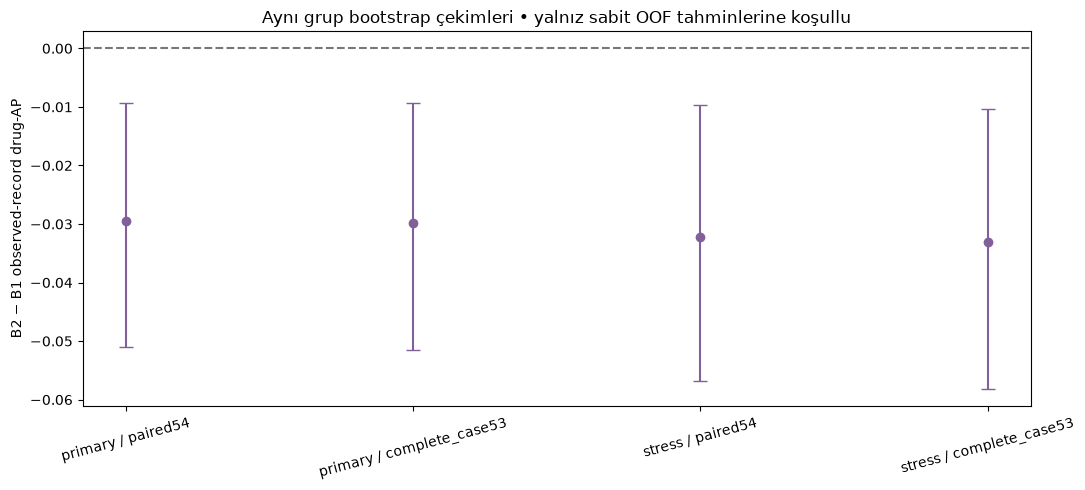

In [7]:
delta=read('paired_B2_minus_B1_group_CI.csv');display(delta[delta.family.eq('PT')].drop(columns=['semantics','CI_interpretation']))
display(read('bootstrap_design.csv').drop(columns=['semantics']))
fig,ax=plt.subplots(figsize=(11,5));f=delta[delta.family.eq('PT')&delta.metric.eq('drug_macro_AP')].copy();xx=np.arange(len(f));ax.errorbar(xx,f.B2_minus_B1,yerr=np.vstack([f.B2_minus_B1-f.CI95_low,f.CI95_high-f.B2_minus_B1]).astype(float),fmt='o',capsize=5,color='#805f9b');ax.axhline(0,color='#777',ls='--');ax.set_xticks(xx,f.protocol+' / '+f.scope,rotation=15);ax.set(ylabel='B2 − B1 observed-record drug-AP',title='Aynı grup bootstrap çekimleri • yalnız sabit OOF tahminlerine koşullu');plt.tight_layout();plt.savefig(FIG/'06_paired_difference_group_CI.png',dpi=160);plt.show()

**Yorum:** Ana PT ortak kapsam farkı yaklaşık −0,029; koşullu %95 grup-bootstrap aralığı yaklaşık [−0,051, −0,009]. Bu ilk sabit protokolde B2'nin üstünlüğü görülmedi. Proteinlerin biyolojik olarak faydasız olduğu veya başka modelin de başarısız olacağı sonucu çıkarılmaz; küçük örneklem, özellik boyutu, kaynak ve hedef kapsamı sınırlıdır. CI'nın sıfırı dışlaması bütün eğitim sürecinin belirsizliğiyle kanıtlanmış genel üstünlük iddiasına çevrilmez. Sonuca göre C/split/PT/seed değiştirilmedi.

## 7. Model uyumu ve yeniden üretim izi

In [8]:
provenance=read('model_fit_provenance.csv');display(provenance.head(10).drop(columns=['semantics']))
example=ROOT/'models/WP08_baseline_v1/primary_o01_final_PT_B1_selected.json';md=json.loads(example.read_text(encoding='utf-8'))
display(pd.DataFrame([{'model_version':md['model_version'],'C':md['C'],'seed':md['seed'],'sklearn':md['sklearn_version'],'feature_dimension':md['feature_dimension'],'train_drugs':len(md['train_drug_ids']),'fitted_classes':len(md['fitted_classes']),'parameter_sha256':md['parameters_sha256']}]))
display(pd.DataFrame({'train_fit_drug_id':md['train_drug_ids']}))
import plotly.graph_objects as go
f=drug[drug.protocol.eq('primary')&drug.family.eq('PT')&drug.scope.eq('paired54')].copy()
f['drug_AP_num']=pd.to_numeric(f.drug_AP,errors='coerce');pivot=f.pivot(index='drug_id',columns='model',values='drug_AP_num')
fig=go.Figure()
for model in ['B1','B2']:fig.add_trace(go.Scatter(x=pivot.index,y=pivot[model],mode='markers',name=model,hovertemplate='%{x}<br>Observed-record drug AP=%{y:.3f}<extra>'+model+'</extra>'))
fig.update_layout(title='Ortak kapsamda ilaç başına observed-record AP • klinik risk değil',xaxis_title='DrugBank ID',yaxis_title='Drug AP',height=650,width=1200)
fig.write_html(FIG/'per_drug_proxy_AP_interactive.html',include_plotlyjs=True,full_html=True)

,context,phase,family,model,C,model_fit_drugs,chemical_fit_drugs,protein_fit_accessions,fitted_classes,parameter_file,parameters_sha256,test_drugs_in_fit,seed
0,primary_o01_final,outer_train_final_fit,historical30,B1,10.0,43,43,125,30,models\WP08_baseline_v1\primary_o01_final_historical30_B1_selected.npz,ac5275db31be110dc78ec4b2bdb39fdae4c1ebca02fc02bd298eb4bcfae9472e,0,20261106
1,primary_o01_final,outer_train_final_fit,historical30,B2,0.1,48,43,125,30,models\WP08_baseline_v1\primary_o01_final_historical30_B2_selected.npz,bc250669a90cb0ae230e753311ba44b592ce3d809847a42ce567b62fd2504c86,0,20261106
2,primary_o01_final,outer_train_final_fit,PT,B1,0.1,43,43,125,220,models\WP08_baseline_v1\primary_o01_final_PT_B1_selected.npz,ea967157b1fce12de80577d1c7017bd0a9dc4e589e965ae1b09adcb351fffc7d,0,20261106
3,primary_o01_final,outer_train_final_fit,PT,B2,0.1,48,43,125,240,models\WP08_baseline_v1\primary_o01_final_PT_B2_selected.npz,24b345a8c8df50f6759a553e48664d15b830d22017d96b0fe658409cdf51731a,0,20261106
4,primary_o01_i01,inner_train_fit,historical30,B1,0.1,29,29,92,30,models\WP08_baseline_v1\primary_o01_i01_historical30_B1_C0.1.npz,2e2ab152b92981bf4d40b58102a19923450e0369db1e7c89d7362edf5e9bfced,0,20261106
5,primary_o01_i01,inner_train_fit,historical30,B1,1.0,29,29,92,30,models\WP08_baseline_v1\primary_o01_i01_historical30_B1_C1.npz,a85108975f8d9012bfd4036beb3019a09bd0abfd2b2cb29571017cbd9d05e429,0,20261106
6,primary_o01_i01,inner_train_fit,historical30,B1,10.0,29,29,92,30,models\WP08_baseline_v1\primary_o01_i01_historical30_B1_C10.npz,4949d87f1a895bc2e4623e3c29293ca1bb7a3f805437994940b03282d87e8116,0,20261106
7,primary_o01_i01,inner_train_fit,historical30,B2,0.1,32,29,92,30,models\WP08_baseline_v1\primary_o01_i01_historical30_B2_C0.1.npz,213bc1a484a5c5d23fa28fdf9b7aee26f416b638e9e89f208fc9745d2fc0be08,0,20261106
8,primary_o01_i01,inner_train_fit,historical30,B2,1.0,32,29,92,30,models\WP08_baseline_v1\primary_o01_i01_historical30_B2_C1.npz,297a244afe5a64248494fdfd4029f96e38d85a6a26b5ccae76ccd42995721662,0,20261106
9,primary_o01_i01,inner_train_fit,historical30,B2,10.0,32,29,92,30,models\WP08_baseline_v1\primary_o01_i01_historical30_B2_C10.npz,3917074e688f7d34b00223f62cf5a81aceab527501836d7d38d3745e20100ac3,0,20261106


,model_version,C,seed,sklearn,feature_dimension,train_drugs,fitted_classes,parameter_sha256
0,WP08-observed-record-L2LR-v1,0.1,20261106,1.9.0,6,43,220,ea967157b1fce12de80577d1c7017bd0a9dc4e589e965ae1b09adcb351fffc7d


,train_fit_drug_id
0,DB00199
1,DB00207
2,DB00259
3,DB00301
4,DB00303
5,DB00319
6,DB00359
7,DB00415
8,DB00417
9,DB00440


**Kapanış:** Bu ilk baseline eğitimi kullanıcı onayıyla çalıştırıldı; onay öncesi hazırlık dosyaları değiştirilmedi. Her parametre bundle'ında gerçek split hash'i, C, train ID'leri, dönüşüm fit kaynakları, özellik/target sözlüğü, seed ve sürüm bulunur. Model sonuçları test doğrulamasından sonra Türkçe deney raporu ve model kartında açıklanır. WP09'a geçilmez; PPI/ATC/RF/MLP/context kendiliğinden eklenmez.

[Deney raporu](../reports/WP08_BASELINE_RESULTS.md), [model kartı](../reports/WP08_BASELINE_MODEL_CARD.md). Yöntem referansları: [lojistik regresyon](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [AP](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html), [AUROC](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html).